In [2]:
import chinese_calendar
print(chinese_calendar.__version__)

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import Dataset, DataLoader, TensorDataset
import matplotlib.pyplot as plt
import random
import math
from datetime import datetime
import matplotlib.dates as mdates
from chinese_calendar import is_holiday
import sxtwl

# 设置随机种子以确保可重复性
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# 检查是否有可用的GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用设备: {device}")

1.10.0
使用设备: cuda


In [3]:
# 读取数据
df = pd.read_excel(r"d:\D盘桌面\小论文python项目\数据汇总表1.7.xlsx")
df_first_1082 = df.iloc[:1082]  # 选取前1082行（索引0~1081）
df_first_1146 = df.iloc[:1146]  # 选取前1146行（索引0~1145）

df1 = df['lh00close'].iloc[:1082]  # 选取前1082行（索引0~1081）
df2 = df['lh00close'].iloc[:1146]  # 选取前1146行（索引0~1145）
df['date1'] = pd.to_datetime(df.iloc[:, 0])  #将第一列转换为 datetime 类型赋值给新的列"date"
df.set_index('date1', inplace=True)
df.index.name = None

# 从时间索引中提取时间特征
df['year'] = df.index.year
df['month'] = df.index.month
df['day'] = df.index.day
df['weekday'] = df.index.dayofweek  # 0是周一，6是周日

# 取前1082行的时间特征
time_features_1082  = df[['year', 'month', 'day', 'weekday']].iloc[:1146]
time_features_1476  = df[['year', 'month', 'day', 'weekday']].iloc[:1476]
print("时间特征样例：")
print(time_features_1082.head())
print(time_features_1082.tail())
print(time_features_1082.shape)

# 提取特征和目标列
feature_columns = [
                   '出栏价:生猪:全国','出栏量:生猪:当季值','全国:能繁母猪存栏','全国:生猪存栏','全国:生猪定点屠宰企业屠宰量',
                   '全国:生猪定点屠宰企业屠宰量:同比',
                   '全国:生猪定点屠宰企业屠宰量:环比','成本:规模养殖生猪','净利润:规模养殖生猪','平均批发价:猪肉',
                   '猪粮比价:全国','猪肉:进口数量:当月值',
                   '人均可支配收入','CPI:当月值','CPI:当月同比','CPI:环比','国债收益率:10年','国债收益率:1年', 
                   '养殖利润:外购仔猪',
                   '养殖利润:自繁自养生猪','市场价:猪肉:全国','现货价:豆粕','现货价:玉米',
                   '期货收盘价(连续):豆粕','期货收盘价(活跃):豆粕','期货收盘价(连续):黄玉米',
                   '期货收盘价(活跃):黄玉米','二元母猪价格','仔猪价格',
                   'lh00open', 'lh00high', 'lh00settle', 'lh00close', 'lh00low', 'lh00volume', 
                   'lh00money', 'lh00hold', 'lh00holdchange', 'lh01open', 'lh01high', 'lh01settle', 
                   'lh01close', 'lh01low', 'lh01volume', 'lh01money', 'lh01hold', 'lh01holdchange', 
                   'lh02open', 'lh02high', 'lh02settle', 'lh02close', 'lh02low', 'lh02volume', 
                   'lh02money', 'lh02hold', 'lh02holdchange', 'lh03open', 'lh03high', 'lh03settle', 
                   'lh03close', 'lh03low', 'lh03volume', 'lh03money', 'lh03hold', 'lh03holdchange']
target_column = 'lh00close'  

时间特征样例：
            year  month  day  weekday
2021-01-08  2021      1    8        4
2021-01-11  2021      1   11        0
2021-01-12  2021      1   12        1
2021-01-13  2021      1   13        2
2021-01-14  2021      1   14        3
            year  month  day  weekday
2025-09-22  2025      9   22        0
2025-09-23  2025      9   23        1
2025-09-24  2025      9   24        2
2025-09-25  2025      9   25        3
2025-09-26  2025      9   26        4
(1146, 4)


In [4]:
# 获取列数
num_columns = df.shape[1]
print(f"df 的列数为: {num_columns}")

print(df.columns)

df 的列数为: 70
Index(['date', '出栏价:生猪:全国', '出栏量:生猪:当季值', '全国:能繁母猪存栏', '全国:生猪存栏',
       '全国:生猪定点屠宰企业屠宰量', '全国:生猪定点屠宰企业屠宰量:同比', '全国:生猪定点屠宰企业屠宰量:环比', '成本:规模养殖生猪',
       '净利润:规模养殖生猪', '平均批发价:猪肉', '猪粮比价:全国', '猪肉:进口数量:当月值', '人均可支配收入',
       'CPI:当月值', 'CPI:当月同比', 'CPI:环比', '国债收益率:10年', '国债收益率:1年', '养殖利润:外购仔猪',
       '养殖利润:自繁自养生猪', '市场价:猪肉:全国', '现货价:豆粕', '现货价:玉米', '期货收盘价(连续):豆粕',
       '期货收盘价(活跃):豆粕', '期货收盘价(连续):黄玉米', '期货收盘价(活跃):黄玉米', '二元母猪价格', '仔猪价格',
       'lh00open', 'lh00high', 'lh00settle', 'lh00close', 'lh00low',
       'lh00volume', 'lh00money', 'lh00hold', 'lh00holdchange', 'lh01open',
       'lh01high', 'lh01settle', 'lh01close', 'lh01low', 'lh01volume',
       'lh01money', 'lh01hold', 'lh01holdchange', 'lh02open', 'lh02high',
       'lh02settle', 'lh02close', 'lh02low', 'lh02volume', 'lh02money',
       'lh02hold', 'lh02holdchange', 'lh03open', 'lh03high', 'lh03settle',
       'lh03close', 'lh03low', 'lh03volume', 'lh03money', 'lh03hold',
       'lh03holdchange', 'year', 'month',

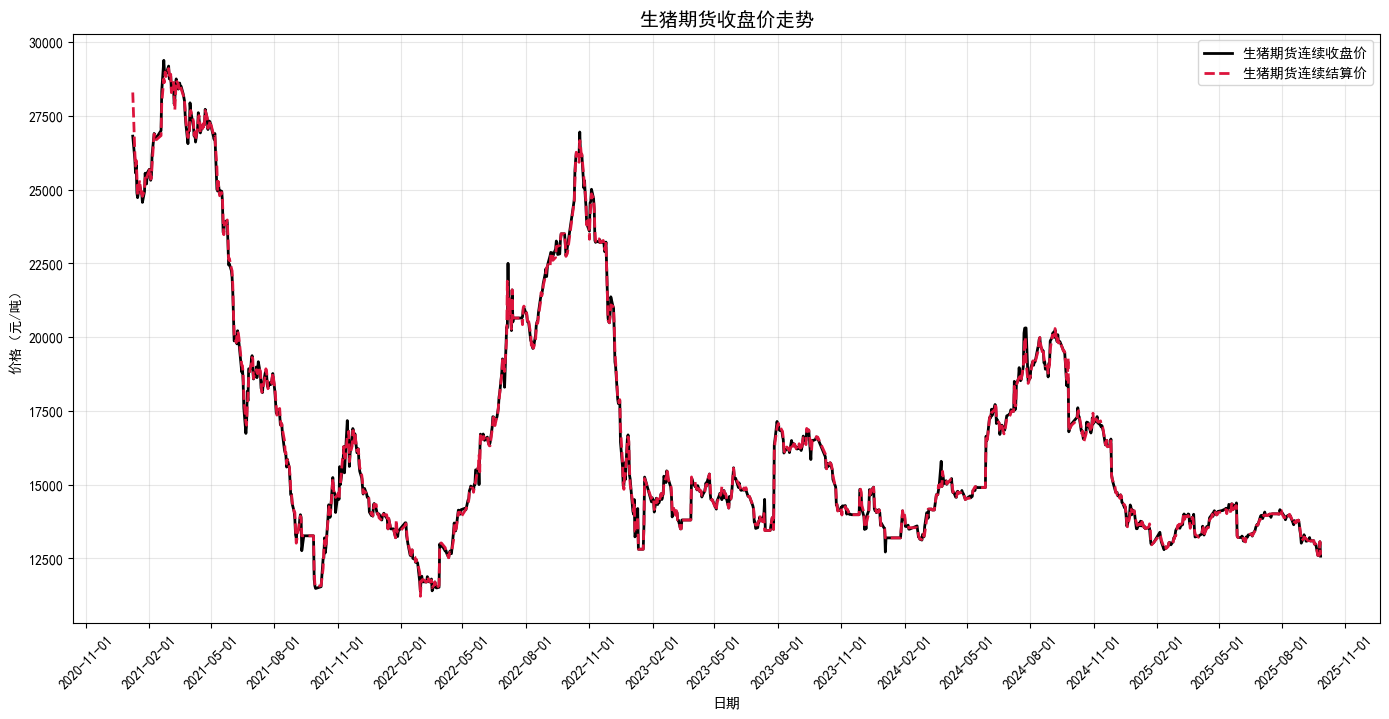

In [5]:
from turtle import color
import matplotlib as mpl
from matplotlib.lines import lineStyles
mpl.rcParams['font.sans-serif'] = ['SimHei']       # 使用黑体
mpl.rcParams['axes.unicode_minus'] = False         # 解决负号显示问题

plt.figure(figsize=(14, 7))
plt.plot(df['lh00close'],color='black',linewidth=2,linestyle='-',label='生猪期货连续收盘价')   # x轴默认使用 DataFrame 的索引（通常是日期）
plt.plot(df['lh00settle'],color='#DC143C',linewidth=2,linestyle='--',label='生猪期货连续结算价')   # x轴默认使用 DataFrame 的索引（通常是日期）

plt.grid(True, linestyle='-', alpha=0.3) 
plt.legend()                   #在图表上添加网格线，便于读取具体数值。
plt.xlabel('日期')
plt.ylabel('价格（元/吨）')
plt.title('生猪期货收盘价走势', fontsize=14)
plt.xticks(rotation=45)           # # 将 x 轴标签旋转 45 度
plt.tight_layout()                #自动调整图形的布局，确保所有元素（如图例、标签等）都不会超出图形边界，避免显示不全的问题
# 设置 x 轴日期格式
ax = plt.gca()                    # 获取当前坐标轴对象
date_format = mdates.DateFormatter('%Y-%m-%d')  # 格式：年-月-日
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.show()

In [6]:
# 1.设置模型输入输出序列长度
input_seq_len_param = 365    # 输入序列长度(361天)
output_seq_len_param = 90    # 输出序列长度(90天)

# 2.设置训练集和验证集比例，为避免在测试集数据出现泄露，只用测试集之前的数据作为训练集和测试集
total_seq_len = len(df1)
train_seq_len = total_seq_len - output_seq_len_param
total_section = total_seq_len - input_seq_len_param - output_seq_len_param + 1    #总切片长度
train_section = train_seq_len - input_seq_len_param - output_seq_len_param + 1    #可用于训练的切片长度
train_ratio = train_section/total_section

train_ratio_param = 0.98*train_ratio
val_ratio_param = 0.02*train_ratio
print(train_ratio_param, val_ratio_param)

# 3.设置正余弦时间编码维度
sctf_size_param = 128
cytf_size_param = 8
teacher_forcing_ratio_param = 0.1

# 4.模型输入输出特征维度大小
input_size_param = len(feature_columns)  # 输入特征数
print(input_size_param)
hidden_size_param = 256 # 隐藏层大小
output_size_param = 1  # 输出特征数(期货收盘价)
time_embed_size_param = 128  # 时间编码维度
hist_flat_param_size = 5   # 历史特征数(20个交易日)

# 5.设置训练参数
n_epochs_param = 30
patience_param = 10

# 6.设置学习率和权重衰减
lr_param = 1e-5
weight_decay_param = 1e-6


0.8395541401273886 0.01713375796178344
65


In [7]:
#正余弦时间编码
time_series = df['date']
def convert_to_unix_epoch(time_series):
    # 计算每个日期与1970-01-01之间的天数差
    epoch_start = datetime(1970, 1, 1)
    unix_epochs = (time_series - epoch_start).dt.days
    return unix_epochs
unix_epochs = convert_to_unix_epoch(time_series)
print(unix_epochs.head())
print(unix_epochs.tail())

def sinusoidal_encoding(unix_epochs, dim=128):
    # 正余弦编码
    unix_epochs = unix_epochs.values
    encoded = np.zeros((len(unix_epochs), dim))
    position = unix_epochs[:, np.newaxis]  # 转换为二维数组以便广播
    div_term = 1 / (10000 ** (np.arange(0, dim, 2) / dim))
    
    encoded[:, 0::2] = np.sin(position * div_term)
    encoded[:, 1::2] = np.cos(position * div_term)
    
    return encoded

sctf_size = sctf_size_param
encoded_sincos_embeding_time = sinusoidal_encoding(unix_epochs, sctf_size)
print(encoded_sincos_embeding_time.shape)
print(encoded_sincos_embeding_time[:1,0:5])


2021-01-08    18635
2021-01-11    18638
2021-01-12    18639
2021-01-13    18640
2021-01-14    18641
Name: date, dtype: int64
2026-12-28    20815
2026-12-29    20816
2026-12-30    20817
2026-12-31    20818
2027-01-01    20819
Name: date, dtype: int64
(1476, 128)
[[-0.80019548  0.59973927  0.89848036 -0.43901371  0.45686505]]


In [8]:
# 循环编码时间特征
def create_cyclical_time_features(datetime_series):
    """
    为时间序列创建循环编码特征。
    参数:
        datetime_series: pandas Series, 包含datetime对象。
    返回:
        DataFrame: 包含循环编码特征。
    """
    df_features = pd.DataFrame(index=datetime_series.index)
    
    # 1. 提取基本时间单位
    df_features['day_of_year'] = datetime_series.dt.dayofyear  # 一年中的第几天 (1-365/366)
    df_features['month'] = datetime_series.dt.month           # 月份 (1-12)
    df_features['week_of_year'] = datetime_series.dt.isocalendar().week  # 一年中的第几周
    df_features['day_of_week'] = datetime_series.dt.dayofweek # 一周中的第几天 (0-6)
    
    # 2. 对每个周期特征进行正弦余弦编码
    # 年份周期（年复一年）
    df_features['day_of_year_sin'] = np.sin(2 * np.pi * df_features['day_of_year'] / 365.25)
    df_features['day_of_year_cos'] = np.cos(2 * np.pi * df_features['day_of_year'] / 365.25)
    
    # 月份周期（月复一月）
    df_features['month_sin'] = np.sin(2 * np.pi * df_features['month'] / 12)
    df_features['month_cos'] = np.cos(2 * np.pi * df_features['month'] / 12)
    
    # 周周期（周复一周）
    df_features['week_sin'] = np.sin(2 * np.pi * df_features['week_of_year'] / 52)
    df_features['week_cos'] = np.cos(2 * np.pi * df_features['week_of_year'] / 52)
    
    # 日周期（日复一日，如果需要）
    df_features['day_of_week_sin'] = np.sin(2 * np.pi * df_features['day_of_week'] / 7)
    df_features['day_of_week_cos'] = np.cos(2 * np.pi * df_features['day_of_week'] / 7)

    # 可选：保留年份作为线性趋势特征
    # df_features['year'] = datetime_series.dt.year
    
    return df_features.drop(['day_of_year', 'month', 'week_of_year', 'day_of_week'], axis=1)

# 使用示例
cyclical_features = create_cyclical_time_features(time_series)
print("循环时间编码维度:",cyclical_features.shape)

循环时间编码维度: (1476, 8)


In [9]:
# 提取农历特征

def extract_lunar_features_from_index(timestamp):
    """
    从 pandas Timestamp 提取农历特征（使用 sxtwl）
    """
    year = timestamp.year
    month = timestamp.month
    day = timestamp.day
    
    # 使用 sxtwl 转换公历到农历
    lunar_day = sxtwl.fromSolar(year, month, day)
    
    lunar_year = lunar_day.getLunarYear()
    lunar_month = lunar_day.getLunarMonth()   # 1~12，闰月也返回数字（如闰四月=4）
    lunar_day_num = lunar_day.getLunarDay()
    is_leap = int(lunar_day.isLunarLeap())         # 是否为闰月（布尔值）
    is_hol = int(is_holiday(timestamp.date()))     # 是否为中国法定节假日
    
    return pd.Series({
        'lunar_year': lunar_year,
        'lunar_month': lunar_month,
        'lunar_day': lunar_day_num,
        'is_leap_month': is_leap,
        'is_holiday': is_hol
    })

# 应用函数到每一行的索引（公历日期）
lunar_features_df = time_features_1082.index.to_series().apply(extract_lunar_features_from_index)
lunar_features_df.index = time_features_1082.index  # 对齐索引

# 合并原始数据与农历特征
result_df = pd.concat([time_features_1082, lunar_features_df], axis=1)

# 输出验证
print("前5行：")
print(result_df.head())
print("\n后5行：")
print(result_df.tail())
print("\n最终形状：", result_df.shape)  # 应为 (1146, 9)

前5行：
            year  month  day  weekday  lunar_year  lunar_month  lunar_day  \
2021-01-08  2021      1    8        4        2020           11         25   
2021-01-11  2021      1   11        0        2020           11         28   
2021-01-12  2021      1   12        1        2020           11         29   
2021-01-13  2021      1   13        2        2020           12          1   
2021-01-14  2021      1   14        3        2020           12          2   

            is_leap_month  is_holiday  
2021-01-08              0           0  
2021-01-11              0           0  
2021-01-12              0           0  
2021-01-13              0           0  
2021-01-14              0           0  

后5行：
            year  month  day  weekday  lunar_year  lunar_month  lunar_day  \
2025-09-22  2025      9   22        0        2025            8          1   
2025-09-23  2025      9   23        1        2025            8          2   
2025-09-24  2025      9   24        2        2025      

In [10]:
# 融合时间编码和循环时间编码
time_result_df = pd.concat([result_df, cyclical_features], axis=1)
print(time_result_df.head())
print(time_result_df.tail())
print(time_result_df.shape)  # 应为 (1146, 15)


              year  month   day  weekday  lunar_year  lunar_month  lunar_day  \
2021-01-08  2021.0    1.0   8.0      4.0      2020.0         11.0       25.0   
2021-01-11  2021.0    1.0  11.0      0.0      2020.0         11.0       28.0   
2021-01-12  2021.0    1.0  12.0      1.0      2020.0         11.0       29.0   
2021-01-13  2021.0    1.0  13.0      2.0      2020.0         12.0        1.0   
2021-01-14  2021.0    1.0  14.0      3.0      2020.0         12.0        2.0   

            is_leap_month  is_holiday  day_of_year_sin  day_of_year_cos  \
2021-01-08            0.0         0.0         0.137185         0.990545   
2021-01-11            0.0         0.0         0.188099         0.982150   
2021-01-12            0.0         0.0         0.204966         0.978769   
2021-01-13            0.0         0.0         0.221772         0.975099   
2021-01-14            0.0         0.0         0.238513         0.971139   

            month_sin  month_cos  week_sin  week_cos  day_of_week_si

In [11]:
# 1. 划分时间序列数据 (按时间顺序)
total = len(df_first_1082)
train_size = int(total * train_ratio_param)
val_size = int(total * val_ratio_param)

# 训练集: [0, train_size)
train_df = df_first_1146.iloc[:train_size]
# 验证集: [train_size, train_size+val_size)
val_df = df_first_1146.iloc[train_size:train_size+val_size]
# 测试集: [train_size+val_size, end)
test_df = df_first_1146.iloc[train_size+val_size:]

# 2. 用训练集拟合归一化器
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# 仅用训练集特征拟合
scaler_X.fit(train_df[feature_columns])
# 仅用训练集目标拟合
scaler_y.fit(train_df[[target_column]])

# 3. 标准化所有数据
# 仅对特征列进行标准化
features_scaled = scaler_X.transform(df_first_1146[feature_columns])
# 只对目标列进行标准化
target_scaled = scaler_y.transform(df_first_1146[[target_column]])  

print("标准化后的特征列形状:",features_scaled.shape,target_scaled.shape)


标准化后的特征列形状: (1146, 65) (1146, 1)


In [12]:
import numpy as np
import pandas as pd
from PyEMD.EMD import EMD
from PyEMD.EEMD import EEMD
from scipy.stats import ttest_1samp

# ==============================================
# 【工具函数1】EEMD分解单列数据
# ==============================================
def decompose_single_series(series):
    eemd = EEMD(trials=100, noise=0.05)  # 论文标准参数
    imfs = eemd(series.values)  # 返回 (n_imf, n_samples)
    res = series.values - np.sum(imfs, axis=0)
    return imfs, res

# ==============================================
# 【工具函数2】Fine-to-coarse 高低频重构（你论文里的方法）
# ==============================================
def fine_to_coarse_reconstruct(imfs):
    n_imfs, n_len = imfs.shape
    high_freq = np.zeros(n_len)
    low_freq = np.zeros(n_len)
    
    # 逐步累加 IMF 并做 t 检验
    for i in range(n_imfs):
        s_i = np.sum(imfs[:i+1], axis=0)
        t_stat, p_val = ttest_1samp(s_i, 0.0)
        
        # 均值显著偏离 0 → 从这里开始分为低频
        if p_val < 0.05:
            high_freq = np.sum(imfs[:i], axis=0) if i > 0 else np.zeros(n_len)
            low_freq = np.sum(imfs[i:], axis=0)
            break
    else:
        # 所有IMF累加都不偏离0 → 全部是高频
        high_freq = np.sum(imfs, axis=0)
    
    return high_freq, low_freq

# ==============================================
# 【核心函数】对 65 列特征批量做 EEMD + 高低频重构
# 输入：(1146, 65)
# 输出：(1146, 260) → [原始, 高频, 低频, 残差]
# ==============================================
def apply_eemd_to_all_features(features_scaled):
    n_samples, n_features = features_scaled.shape
    eemd_features = []
    
    for col_idx in range(n_features):
        # 取出单列 (1146,)
        series = features_scaled[:, col_idx]
        series_ts = pd.Series(series)
        
        # 1. EEMD 分解
        imfs, residual = decompose_single_series(series_ts)
        
        # 2. 高低频重构
        high, low = fine_to_coarse_reconstruct(imfs)
        
        # 3. 收集 4 个分量
        eemd_features.append(series)       # 原始
        eemd_features.append(high)         # 高频
        eemd_features.append(low)          # 低频
        eemd_features.append(residual)     # 残差
    
    # 拼接 → (1146, 65*4=260)
    final_features = np.column_stack(eemd_features)
    return final_features

# ==============================================
# 【调用方法】直接处理你的 (1146,65)
# ==============================================
final_features_260 = apply_eemd_to_all_features(features_scaled)

print("✅ EEMD + 高低频重构完成！")
print("最终特征维度：", final_features_260.shape)  # 输出 (1146, 260)

✅ EEMD + 高低频重构完成！
最终特征维度： (1146, 260)


In [13]:
import numpy as np
import torch

def create_sequences(features, target, time_feats, sincos_feats, cyclical_feats, in_len, out_len):
    """
    构建滑动窗口序列数据
    """
    total_len = len(features)
    # 动态计算循环次数，避免硬编码
    max_start_idx = 1082 - in_len - out_len + 1
    
    X_list, y_list = [], []
    enc_tf_list, dec_tf_list = [], []
    enc_sc_list, dec_sc_list = [], []
    enc_cy_list, dec_cy_list = [], []

    for i in range(max_start_idx):
        # 1. 切片索引定义
        start_in = i
        end_in = i + in_len
        start_out = end_in
        end_out = start_out + out_len

        # 2. 数值特征
        X_list.append(features[start_in:end_in])
        y_list.append(target[start_out:end_out])

        # 3. 时间特征 (Time Features)
        enc_tf_list.append(time_feats.iloc[start_in:end_in].to_numpy(dtype=np.float32))
        dec_tf_list.append(time_feats.iloc[start_out:end_out].to_numpy(dtype=np.float32))

        # 4. 正余弦编码 (SinCos Embeddings)
        enc_sc_list.append(sincos_feats[start_in:end_in])
        dec_sc_list.append(sincos_feats[start_out:end_out])

        # 5. 循环特征 (Cyclical Features)
        enc_cy_list.append(cyclical_feats.iloc[start_in:end_in].to_numpy(dtype=np.float32))
        dec_cy_list.append(cyclical_feats.iloc[start_out:end_out].to_numpy(dtype=np.float32))

    # 6. 统一转换为 Tensor
    # 使用 np.stack 比 np.array 更稳健，特别是当内部已经是 numpy 数组时
    tensors = [torch.FloatTensor(np.stack(arr)) for arr in [
        X_list, y_list, 
        enc_tf_list, dec_tf_list, 
        enc_sc_list, dec_sc_list, 
        enc_cy_list, dec_cy_list
    ]]

    # 解包并打印形状
    X_feat, Y_label, enc_tf, dec_tf, enc_sc, dec_sc, enc_cy, dec_cy = tensors
    
    print(f"✅ 数据构建完成:")
    print(f"   输入/输出形状: {X_feat.shape} / {Y_label.shape}")
    print(f"   时间特征形状: {enc_tf.shape} / {dec_tf.shape}")
    print(f"   正余弦形状:   {enc_sc.shape} / {dec_sc.shape}")
    print(f"   循环特征形状: {enc_cy.shape} / {dec_cy.shape}")

    # 返回一个字典，方便后续管理，或者保持元组形式
    return {
        'X': X_feat,
        'y': Y_label,
        'enc_time': enc_tf,
        'dec_time': dec_tf,
        'enc_sincos': enc_sc,
        'dec_sincos': dec_sc,
        'enc_cyclical': enc_cy,
        'dec_cyclical': dec_cy
    }

# --- 调用部分 ---

# 设置序列长度
input_seq_len = input_seq_len_param
output_seq_len = output_seq_len_param

# 创建序列数据
# 注意：这里假设 features_scaled 是 numpy 数组，time_result_df 是 DataFrame
dataset_dict = create_sequences(
    final_features_260, 
    target_scaled, 
    time_result_df,                # 对应 time_features
    encoded_sincos_embeding_time,  # 对应 sincos embeddings
    cyclical_features,             # 对应 cyclical features
    input_seq_len, 
    output_seq_len
)

# 后续使用时直接取值，例如:
# X_train = dataset_dict['X']
# y_train = dataset_dict['y']


✅ 数据构建完成:
   输入/输出形状: torch.Size([628, 365, 260]) / torch.Size([628, 90, 1])
   时间特征形状: torch.Size([628, 365, 17]) / torch.Size([628, 90, 17])
   正余弦形状:   torch.Size([628, 365, 128]) / torch.Size([628, 90, 128])
   循环特征形状: torch.Size([628, 365, 8]) / torch.Size([628, 90, 8])


In [14]:
import torch
from torch.utils.data import DataLoader, TensorDataset

def build_seq2seq_dataloaders(data_tensors, batch_size=32, train_ratio=0.7, val_ratio=0.2, device=None):
    """
    通用数据加载器构建函数
    :param data_tensors: 包含所有输入张量的列表 [X, Y, enc_tf, dec_tf, ...]
    :param batch_size: 批大小
    :param train_ratio: 训练集比例
    :param val_ratio: 验证集比例
    :param device: 设备
    """
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    total = len(data_tensors[0])
    train_size = int(total * train_ratio)
    val_size = int(total * val_ratio)
    
    print(f"数据集划分：总 {total} | 训练 {train_size} | 验证 {val_size} | 测试 {total - train_size - val_size}")

    # 1. 批量切片
    # 定义切片范围
    splits = [
        (0, train_size), 
        (train_size, train_size + val_size), 
        (train_size + val_size, total)
    ]
    
    # 存储切分后的数据：[train_data_list, val_data_list, test_data_list]
    # 其中每个 data_list 包含该集合的所有张量 [X, Y, enc_tf, ...]
    split_data = []
    
    for start, end in splits:
        if start >= end: continue # 防止空切片
        # 对每个张量进行切片并移动到设备
        batch_tensors = [t[start:end].to(device) for t in data_tensors]
        split_data.append(batch_tensors)

    train_data, val_data, test_data = split_data

    # 2. 创建 DataLoader
    # 这里的 *data 会将列表解包成 TensorDataset 的参数
    train_loader = DataLoader(TensorDataset(*train_data), batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(TensorDataset(*val_data), batch_size=batch_size, shuffle=False)
    test_loader  = DataLoader(TensorDataset(*test_data), batch_size=batch_size, shuffle=False)
    # trains_loader (用于训练集评估，不 shuffle)
    trains_loader = DataLoader(TensorDataset(*train_data), batch_size=batch_size, shuffle=False)

    return train_loader, val_loader, test_loader, trains_loader

# --- 调用部分 ---

# 将所有张量打包成一个列表，方便管理
all_input_tensors = [
    dataset_dict['X'],          # 0: 主特征
    dataset_dict['y'],            # 1: 标签
    dataset_dict['enc_time'],  # 2: 编码器时间特征
    dataset_dict['dec_time'],  # 3: 解码器时间特征
    dataset_dict['enc_sincos'],     # 4: 编码器正余弦
    dataset_dict['dec_sincos'],     # 5: 解码器正余弦
    dataset_dict['enc_cyclical'],    # 6: 编码器循环特征
    dataset_dict['dec_cyclical']     # 7: 解码器循环特征
]

# 调用函数
train_loader, val_loader, test_loader, trains_loader = build_seq2seq_dataloaders(
    all_input_tensors,
    batch_size=16,
    train_ratio=train_ratio_param,
    val_ratio=val_ratio_param,
    device=device
)

# 验证输出
print("\n验证数据加载器：")
for name, loader in zip(["Train", "Val", "Test", "Trains"], [train_loader, val_loader, test_loader, trains_loader]):
    # 取一个 batch
    batch = next(iter(loader))
    # 打印每个张量的形状
    shapes = [t.shape for t in batch]
    print(f"{name}: {len(batch)} 个张量，形状分别为 {shapes}")

数据集划分：总 628 | 训练 527 | 验证 10 | 测试 91

验证数据加载器：
Train: 8 个张量，形状分别为 [torch.Size([16, 365, 260]), torch.Size([16, 90, 1]), torch.Size([16, 365, 17]), torch.Size([16, 90, 17]), torch.Size([16, 365, 128]), torch.Size([16, 90, 128]), torch.Size([16, 365, 8]), torch.Size([16, 90, 8])]
Val: 8 个张量，形状分别为 [torch.Size([10, 365, 260]), torch.Size([10, 90, 1]), torch.Size([10, 365, 17]), torch.Size([10, 90, 17]), torch.Size([10, 365, 128]), torch.Size([10, 90, 128]), torch.Size([10, 365, 8]), torch.Size([10, 90, 8])]
Test: 8 个张量，形状分别为 [torch.Size([16, 365, 260]), torch.Size([16, 90, 1]), torch.Size([16, 365, 17]), torch.Size([16, 90, 17]), torch.Size([16, 365, 128]), torch.Size([16, 90, 128]), torch.Size([16, 365, 8]), torch.Size([16, 90, 8])]
Trains: 8 个张量，形状分别为 [torch.Size([16, 365, 260]), torch.Size([16, 90, 1]), torch.Size([16, 365, 17]), torch.Size([16, 90, 17]), torch.Size([16, 365, 128]), torch.Size([16, 90, 128]), torch.Size([16, 365, 8]), torch.Size([16, 90, 8])]


In [15]:
# 真实时间特征嵌入层
class RealTimeEmbedding(nn.Module):
    def __init__(self, time_embed_size):
        super(RealTimeEmbedding, self).__init__()
        self.time_embed_size = time_embed_size
        
        # ========== 离散特征嵌入层（共9个）==========
        # 公历部分
        self.year_embedding = nn.Embedding(50, time_embed_size // 8)      # year: 2000-2049 → 50
        self.month_embedding = nn.Embedding(13, time_embed_size // 8)     # month: 1-12
        self.day_embedding = nn.Embedding(32, time_embed_size // 8)       # day: 1-31
        self.weekday_embedding = nn.Embedding(7, time_embed_size // 8)    # weekday: 0-6
        
        # 农历部分
        self.lunar_year_embedding = nn.Embedding(60, time_embed_size // 8)   # lunar_year: 一般60年一甲子，可覆盖多年
        self.lunar_month_embedding = nn.Embedding(13, time_embed_size // 8)  # lunar_month: 1-12（闰月靠 is_leap 区分）
        self.lunar_day_embedding = nn.Embedding(31, time_embed_size // 8)    # lunar_day: 1-30
        
        # 二值特征（is_leap_month, is_holiday）——只有 0/1，用 Embedding(2, ...)
        self.is_leap_embedding = nn.Embedding(2, time_embed_size // 8)
        self.is_holiday_embedding = nn.Embedding(2, time_embed_size // 8)
        
        # 总嵌入维度 = 9 * (time_embed_size // 8)
        discrete_embed_dim = 9 * (time_embed_size // 8)
        continuous_dim = 8  # 后8列是 sin/cos 连续特征

        # 加强版时间融合（2层 MLP）
        self.time_fusion = nn.Sequential(
            nn.Linear(discrete_embed_dim + continuous_dim, time_embed_size * 2),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(time_embed_size * 2, time_embed_size),
        )
        self.ln_time_fusion = nn.LayerNorm(time_embed_size)

        # # 融合层：将 [discrete_embed + continuous] 映射到 time_embed_size
        # self.time_fusion = nn.Linear(discrete_embed_dim + continuous_dim, time_embed_size)
        # self.dropout = nn.Dropout(0.1)
        # self.ln_time_fusion = nn.LayerNorm(time_embed_size)
        
    def forward(self, time_features):
        """
        Args:
            time_features: [batch_size, seq_len, 17]
                列顺序：
                0: year
                1: month
                2: day
                3: weekday
                4: lunar_year
                5: lunar_month
                6: lunar_day
                7: is_leap_month (0/1)
                8: is_holiday (0/1)
                9: day_of_year_sin
                10: day_of_year_cos
                11: month_sin
                12: month_cos
                13: week_sin
                14: week_cos
                15: day_of_week_sin
                16: day_of_week_cos
        Returns:
            [batch_size, seq_len, time_embed_size]
        """
        batch_size, seq_len, total_feat = time_features.shape
        assert total_feat == 17, f"Expected 17 time features, got {total_feat}"
        
        # ====== 提取离散特征并转为 long ======
        years = (time_features[:, :, 0].long() - 2000).clamp(0, 49)
        months = time_features[:, :, 1].long().clamp(1, 12)
        days = time_features[:, :, 2].long().clamp(1, 31)
        weekdays = time_features[:, :, 3].long().clamp(0, 6)
        
        lunar_years = time_features[:, :, 4].long()
        # lunar_year 可能超出 0-59，我们对 60 取模（甲子循环）或 clamp；这里简单 clamp 到 0-59
        lunar_years = (lunar_years - 1900).clamp(0, 59)  # 假设最小年1900，最大1959+ → 可调整
        
        lunar_months = time_features[:, :, 5].long().clamp(1, 12)
        lunar_days = time_features[:, :, 6].long().clamp(1, 30)
        is_leap = time_features[:, :, 7].long().clamp(0, 1)
        is_holiday = time_features[:, :, 8].long().clamp(0, 1)
        
        # ====== 获取嵌入 ======
        embeds = [
            self.year_embedding(years),
            self.month_embedding(months),
            self.day_embedding(days),
            self.weekday_embedding(weekdays),
            self.lunar_year_embedding(lunar_years),
            self.lunar_month_embedding(lunar_months),
            self.lunar_day_embedding(lunar_days),
            self.is_leap_embedding(is_leap),
            self.is_holiday_embedding(is_holiday),
        ]  # 每个都是 [B, L, time_embed_size//8]
        
        discrete_embed = torch.cat(embeds, dim=-1)  # [B, L, 9 * (time_embed_size//8)]
        
        # ====== 提取连续周期特征（第9~16列）======
        continuous_feats = time_features[:, :, 9:17]  # [B, L, 8]
        
        # ====== 拼接离散嵌入 + 连续特征 ======
        combined = torch.cat([discrete_embed, continuous_feats], dim=-1)  # [B, L, D]
        
        # ====== 融合映射 ======
        time_embed = self.time_fusion(combined)
        time_embed = self.ln_time_fusion(time_embed)
        # time_embed = self.dropout(time_embed)
        
        return time_embed

In [16]:

class MultiInputLSTM(nn.Module):
    def __init__(self, input_dim_1=65, input_dim_2=17, input_dim_3=128, 
                 hidden_dim=128, output_seq_len=30, output_dim=1, num_layers=2, dropout=0.2):
        super(MultiInputLSTM, self).__init__()
        
        # 1. 计算总输入维度
        self.total_input_dim = input_dim_1 + input_dim_2 + input_dim_3
        
        # 2. LSTM 层
        # input_size: 拼接后的特征维度 (210)
        # hidden_size: 隐藏层维度
        # batch_first=True: 输入形状为 (Batch, Seq, Feature)
        self.lstm = nn.LSTM(
            input_size=self.total_input_dim, 
            hidden_size=hidden_dim, 
            num_layers=num_layers, 
            batch_first=True, 
            dropout=dropout if num_layers > 1 else 0
        )
        
        # 3. 输出层 (全连接层)
        # 我们将 LSTM 输出的每个时间步 (365个) 映射到 输出序列长度 (90)
        # 输入: hidden_dim, 输出: output_seq_len * output_dim
        self.fc = nn.Linear(hidden_dim, output_seq_len * output_dim)

        # 时间嵌入
        self.time_embedding = RealTimeEmbedding(input_dim_2)
        
        self.output_seq_len = output_seq_len
        self.output_dim = output_dim

    def forward(self, x1, x2, x3):

        # 1. 时间嵌入
        time_emb = self.time_embedding(x2)
        # --- 1. 特征拼接 ---
        # x1: [16, 365, 65]
        # x2: [16, 365, 17]
        # x3: [16, 365, 128]
        # dim=2 表示沿着特征维度拼接
        # x = x1[:, :, 32:33]
        
        # 改成 → 取出 32、97、162、227 四列并拼接
        x = torch.cat((x1, time_emb, x3), dim=2)
        # x = x1
        
        # x 现在的形状: [16, 365, 210]
        
        # --- 2. LSTM 编码 ---
        # lstm_out: [16, 365, 128] (Batch, Time, Hidden)
        # h_n, c_n: 最后的隐藏状态 (我们这里主要利用所有时间步的输出)
        lstm_out, (h_n, c_n) = self.lstm(x)
        
        # --- 3. 输出解码 ---
        # 方法 A: 使用最后一个时间步的输出来预测未来序列 (常见做法)
        # last_hidden: [16, 128]
        last_hidden = lstm_out[:, -1, :] 
        
        # 通过全连接层映射到 [16, 90*1]
        out = self.fc(last_hidden)
        
        # 重塑形状为 [16, 90, 1]
        out = out.view(-1, self.output_seq_len, self.output_dim)
        
        return out

# --- 实例化模型 ---
model = MultiInputLSTM(input_dim_1=260, input_dim_2=time_embed_size_param, input_dim_3=sctf_size_param, 
                 hidden_dim=512, output_seq_len=90, output_dim=1, num_layers=2, dropout=0.2)
# 2. 🔥 关键：把模型搬到 GPU / CPU
model = model.to(device)


In [17]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm  # 用于显示进度条

# 1. 检查数据加载器是否已定义
try:
    print(f"✅ 数据加载器就绪: 训练集 {len(train_loader)} 批, 验证集 {len(val_loader)} 批")
except NameError:
    print("❌ 错误: 请先运行生成 dataloader 的代码块！")

# 2. 定义加权损失函数
def weighted_mse_loss(y_pred, y_true, device, decay_rate=0.98):
    """
    计算带有时间衰减权重的 MSE Loss
    :param decay_rate: 衰减率，越接近 1 衰减越慢，越接近 0 衰减越快
    """
    seq_len = y_pred.size(1) # 获取时间步长度，这里是 90
    
    # 生成权重向量: [1, 2, ..., 90] -> 指数衰减
    # 方法 A: 指数衰减 (推荐)
    # 权重形状: [1, 90, 1]
    time_weights = torch.tensor([decay_rate ** t for t in range(seq_len)], device=device)
    time_weights = time_weights.view(1, seq_len, 1) 
    
    # 方法 B: 线性衰减 (可选)
    # time_weights = torch.linspace(1, 0.1, seq_len, device=device).view(1, seq_len, 1)

    # 计算逐元素误差 (Squared Error)
    squared_error = (y_pred - y_true) ** 2
    
    # 加权: 将误差乘以权重
    # 此时形状仍为 [16, 90, 1]，但前面的值被放大了，后面的值被缩小了
    weighted_error = squared_error * time_weights
    
    # 最后求平均 (注意：这里是对加权后的误差求平均)
    return weighted_error.mean()

# 3. 定义训练与验证函数
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    pbar = tqdm(train_loader, desc="Training", leave=False)
    
    for batch in pbar:
        # 解包数据: 0:X, 1:Y, 2:enc_tf, 4:enc_sc
        x_main = batch[0].to(device)
        x_time = batch[2].to(device)
        x_sincos = batch[4].to(device)
        y_true = batch[1].to(device)

        optimizer.zero_grad()
        y_pred = model(x_main, x_time, x_sincos)
        
        loss = weighted_mse_loss(y_pred, y_true, device, decay_rate=0.98)
        loss.backward()
        
        # 梯度裁剪 (防止梯度爆炸)
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        total_loss += loss.item()
        pbar.set_postfix({'loss': f'{loss.item():.6f}'})
        
    return total_loss / len(train_loader)

def validate(model, val_loader, criterion, device):
    model.eval()
    total_loss = 0.0
    pbar = tqdm(val_loader, desc="Validating", leave=False)
    
    with torch.no_grad():
        for batch in pbar:
            x_main = batch[0].to(device)
            x_time = batch[2].to(device)
            x_sincos = batch[4].to(device)
            y_true = batch[1].to(device)

            y_pred = model(x_main, x_time, x_sincos)
            loss = weighted_mse_loss(y_pred, y_true, device, decay_rate=0.98)
            
            total_loss += loss.item()
            pbar.set_postfix({'val_loss': f'{loss.item():.6f}'})
            
    return total_loss / len(val_loader)

# 4. 配置训练参数与初始化
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 使用设备: {device}")

# 损失函数: MSE
criterion = nn.MSELoss()

# 优化器: Adam + L2正则化 (通过 weight_decay)
learning_rate = 1e-4
l2_lambda = 1e-5
optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=l2_lambda)

# 学习率调整策略 (可选，推荐)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

# 5. 开始训练循环 + 早停机制
epochs = 300
best_val_loss = float('inf')
history = {'train_loss': [], 'val_loss': []}

# ===================== 早停参数 =====================
early_stopping_patience = 60   # 连续30轮不下降就停
early_stopping_counter = 0     # 计数器
early_stop = False              # 早停触发标志
# ====================================================

print(f"📊 开始训练，共 {epochs} 轮...")

for epoch in range(1, epochs + 1):
    # 训练
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    
    # 验证
    val_loss = validate(model, val_loader, criterion, device)
    
    # 记录历史
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    
    # 学习率调整
    scheduler.step(val_loss)

    # ===================== 早停核心逻辑 =====================
    if val_loss < best_val_loss:
        # 损失下降 → 更新最佳值
        best_val_loss = val_loss
        early_stopping_counter = 0
        # 保存最佳模型
        torch.save(model.state_dict(), 'best_lstm_model.pth')
    else:
        # 损失没下降 → 计数器+1
        early_stopping_counter += 1
        # print(f"⚠️  连续 {early_stopping_counter} 轮验证集损失未下降")
        
        # 超过耐心值 → 触发早停
        if early_stopping_counter >= early_stopping_patience:
            print(f"\n🛑 触发早停！连续 {early_stopping_patience} 轮未提升，提前结束训练")
            early_stop = True
            break
    # ========================================================

    # 🔥 每30轮打印一次 + 最后一轮一定打印
    if epoch % 30 == 0 or epoch == epochs:
        print(f"Epoch [{epoch}/{epochs}] | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")

if early_stop:
    print("🎉 训练已提前结束（早停机制）！")
else:
    print("🎉 训练完成！")
print("🎉 训练完成！")

✅ 数据加载器就绪: 训练集 33 批, 验证集 1 批
🚀 使用设备: cuda
📊 开始训练，共 300 轮...


Epoch [30/300] | Train Loss: 0.000287 | Val Loss: 0.000865


Epoch [60/300] | Train Loss: 0.000257 | Val Loss: 0.000874



🛑 触发早停！连续 60 轮未提升，提前结束训练
🎉 训练已提前结束（早停机制）！
🎉 训练完成！


In [23]:
print("最终训练轮数：",epoch)

最终训练轮数： 78


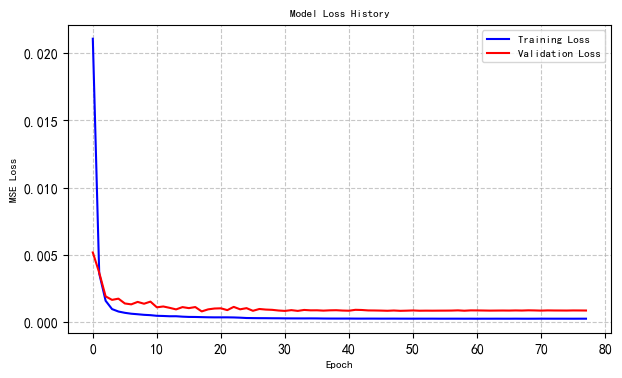

In [18]:
# ==========================================
# 4. 绘制损失曲线
# ==========================================
plt.figure(figsize=(7, 4))
plt.plot(history['train_loss'], label='Training Loss', color='blue')
plt.plot(history['val_loss'], label='Validation Loss', color='red')
plt.title('Model Loss History', fontsize=8)
plt.xlabel('Epoch', fontsize=8)
plt.ylabel('MSE Loss', fontsize=8)
plt.legend(fontsize=8)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [19]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. 预测函数 (保持不变)
def predict_dataset(model, loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for batch in loader:
            x_main = batch[0] 
            x_time = batch[2]
            x_sincos = batch[4]
            y_true = batch[1]
            
            y_pred = model(x_main, x_time, x_sincos)
            
            all_preds.append(y_pred.cpu().numpy())
            all_labels.append(y_true.cpu().numpy())
            
    return np.concatenate(all_preds, axis=0), np.concatenate(all_labels, axis=0)

# 2. 获取预测结果
print("正在预测所有数据集...")
pred_train, label_train = predict_dataset(model, trains_loader, device)
pred_val, label_val = predict_dataset(model, val_loader, device)
pred_test, label_test = predict_dataset(model, test_loader, device)
print("✅ 预测完成。")

# 3. 反归一化 (核心修改部分)
def inverse_transform_3d(scaler, data_3d):
    """
    辅助函数：将 (N, 90, 1) 的形状还原为真实数值
    """
    # 1. 记录原始形状
    original_shape = data_3d.shape
    
    # 2. 重塑为 2D: (N*90, 1)，因为 sklearn 只能处理 2D
    data_2d = data_3d.reshape(-1, 1)
    
    # 3. 使用 scaler_y 进行反归一化
    data_real = scaler_y.inverse_transform(data_2d)
    
    # 4. 恢复为 3D: (N, 90, 1)
    return data_real.reshape(original_shape)

# 对三个集合应用反归一化
print("正在反归一化...")
pred_train_real = inverse_transform_3d(scaler_y, pred_train)
label_train_real = inverse_transform_3d(scaler_y, label_train)

pred_val_real = inverse_transform_3d(scaler_y, pred_val)
label_val_real = inverse_transform_3d(scaler_y, label_val)

pred_test_real = inverse_transform_3d(scaler_y, pred_test)
label_test_real = inverse_transform_3d(scaler_y, label_test)
print("✅ 反归一化完成。")

# --- 新增：打印形状和数值范围检查 ---
print("\n--- 📊 数据形状与数值范围检查 ---")
data_names = ["训练集预测", "训练集真实", "验证集预测", "验证集真实", "测试集预测", "测试集真实"]
data_vars = [pred_train_real, label_train_real, pred_val_real, label_val_real, pred_test_real, label_test_real]

for name, data in zip(data_names, data_vars):
    # 打印形状
    print(f"{name} 形状: {data.shape}")
    # # 打印前一个样本、前5个时间步的数值（用于肉眼检查数值是否正常）
    # print(f"  └─ 数值示例 (Sample 0, T=0~5): {data[0, :5, 0].round(2)}")

# ========================
# ✅ 新增 MAE + MAPE（这里是重点）
# ========================
def mean_absolute_percentage_error(y_true, y_pred, eps=1e-8):
    """ 计算 MAPE """
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()
    mask = np.abs(y_true) > eps
    if not np.any(mask):
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

# 打印误差（现在输出 4 个指标）
def print_metrics(title, pred, label):
    mse  = mean_squared_error(label.flatten(), pred.flatten())
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(label.flatten(), pred.flatten())
    mape = mean_absolute_percentage_error(label, pred)
    r2   = r2_score(label.flatten(), pred.flatten())
     
    print(f"{title}:")
    print(f"  MSE  = {mse:.4f}")
    print(f"  RMSE = {rmse:.4f}")
    print(f"  MAE  = {mae:.4f}")
    print(f"  MAPE = {mape:.2f}%")
    print(f"  R²   = {r2:.4f}\n")

print("\n--- 真实数值下的误差统计 ---")
print_metrics("训练集", pred_train_real, label_train_real)
print_metrics("验证集", pred_val_real, label_val_real)
print_metrics("测试集", pred_test_real[-1], label_test_real[-1])
print_metrics("测试集（后30步）", pred_test_real[-1, -30:], label_test_real[-1, -30:])    


正在预测所有数据集...
✅ 预测完成。
正在反归一化...
✅ 反归一化完成。

--- 📊 数据形状与数值范围检查 ---
训练集预测 形状: (527, 90, 1)
训练集真实 形状: (527, 90, 1)
验证集预测 形状: (10, 90, 1)
验证集真实 形状: (10, 90, 1)
测试集预测 形状: (91, 90, 1)
测试集真实 形状: (91, 90, 1)

--- 真实数值下的误差统计 ---
训练集:
  MSE  = 169807.1719
  RMSE = 412.0767
  MAE  = 298.5564
  MAPE = 1.84%
  R²   = 0.9805

验证集:
  MSE  = 469708.8125
  RMSE = 685.3531
  MAE  = 513.0073
  MAPE = 3.31%
  R²   = 0.8428

测试集:
  MSE  = 2466889.5000
  RMSE = 1570.6335
  MAE  = 1520.3375
  MAPE = 11.19%
  R²   = -14.4597

测试集（后30步）:
  MSE  = 2934456.0000
  RMSE = 1713.0254
  MAE  = 1672.3246
  MAPE = 12.37%
  R²   = -14.4112



In [20]:
def split_data(df, input_seq_len, output_seq_len, train_ratio, val_ratio):
    
    df1 = df
    seqlen_1082 = len(df.iloc[:1082])
    seqlen_section = seqlen_1082 - input_seq_len - output_seq_len + 1
    print(f"时间序列总长度: {seqlen_1082}")
    print(f"时间序列总长度: {seqlen_section}")
    
    train_star_day = input_seq_len + 1
    train_end_day = input_seq_len + int(seqlen_section * train_ratio) 
    val_star_day = input_seq_len + int(seqlen_section * train_ratio) + 1
    val_end_day = input_seq_len + int(seqlen_section * train_ratio) + int(seqlen_section * val_ratio)
    test1_star_day = input_seq_len + int(seqlen_section * train_ratio) + int(seqlen_section * val_ratio) + 1
    test1_end_day = input_seq_len + seqlen_section
    test90_star_day = seqlen_1082 - output_seq_len + 1
    test90_end_day = seqlen_1082
    fu_1_90_star_day = seqlen_1082 +1
    fu_1_90_end_day = seqlen_1082 + output_seq_len


    # 数据集划分
    train_size = int(seqlen_section * train_ratio)
    val_size = int(seqlen_section * val_ratio)
    print(f"数据集划分：训练集 {train_size} 条，验证集 {val_size} 条，测试集 {seqlen_section - train_size - val_size} 条")

    train_star_end_day = df1.iloc[train_star_day - 1:train_end_day]
    val_star_end_day = df1.iloc[val_star_day - 1:val_end_day]
    test1_star_end_day = df1.iloc[test1_star_day - 1:test1_end_day]
    test90_star_end_day = df1.iloc[test90_star_day - 1:test90_end_day]
    fu_1_90_star_end_day = df1.iloc[fu_1_90_star_day - 1:fu_1_90_end_day]

    print(f"训练集开始日期: {train_star_end_day.index[0]}",f"结束日期: {train_star_end_day.index[-1]}")
    print(f"验证集开始日期: {val_star_end_day.index[0]}",f"结束日期: {val_star_end_day.index[-1]}")
    print(f"测试集开始日期: {test1_star_end_day.index[0]}",f"结束日期: {test1_star_end_day.index[-1]}")
    print(f"测试集90天开始日期: {test90_star_end_day.index[0]}",f"结束日期: {test90_star_end_day.index[-1]}")
    # print(f"未来预测开始日期: {fu_1_90_star_end_day.index[0] if fu_1_90_star_end_day is not None else '索引越界'}"
    #       ,f"未来预测结束日期: {fu_1_90_star_end_day.index[-1] if fu_1_90_star_end_day is not None else '索引越界'}")
    
    return train_star_end_day, val_star_end_day, test1_star_end_day, test90_star_end_day

train_ratio_date = train_ratio_param
val_ratio_date = val_ratio_param
star_1_1476_with_dates = df[['lh00close']].iloc[0:1476]                 # 第一行：从DataFrame中选取'lh00close'列的前1476行，结果是DataFrame
print(len(star_1_1476_with_dates))
train_star_end_day, val_star_end_day, test1_star_end_day, test90_star_end_day \
    = split_data(star_1_1476_with_dates, input_seq_len, output_seq_len, train_ratio_date, val_ratio_date)


1476
时间序列总长度: 1082
时间序列总长度: 628
数据集划分：训练集 527 条，验证集 10 条，测试集 91 条
训练集开始日期: 2022-07-14 00:00:00 结束日期: 2024-09-10 00:00:00
验证集开始日期: 2024-09-11 00:00:00 结束日期: 2024-09-26 00:00:00
测试集开始日期: 2024-09-27 00:00:00 结束日期: 2025-02-18 00:00:00
测试集90天开始日期: 2025-02-18 00:00:00 结束日期: 2025-06-30 00:00:00


时间序列总长度: 1082
时间序列总长度: 628
数据集划分：训练集 527 条，验证集 10 条，测试集 91 条
训练集开始日期: 2022-07-14 00:00:00 结束日期: 2024-09-10 00:00:00
验证集开始日期: 2024-09-11 00:00:00 结束日期: 2024-09-26 00:00:00
测试集开始日期: 2024-09-27 00:00:00 结束日期: 2025-02-18 00:00:00
测试集90天开始日期: 2025-02-18 00:00:00 结束日期: 2025-06-30 00:00:00
✅ 图片已保存至: LSTM期货预测走势图.png


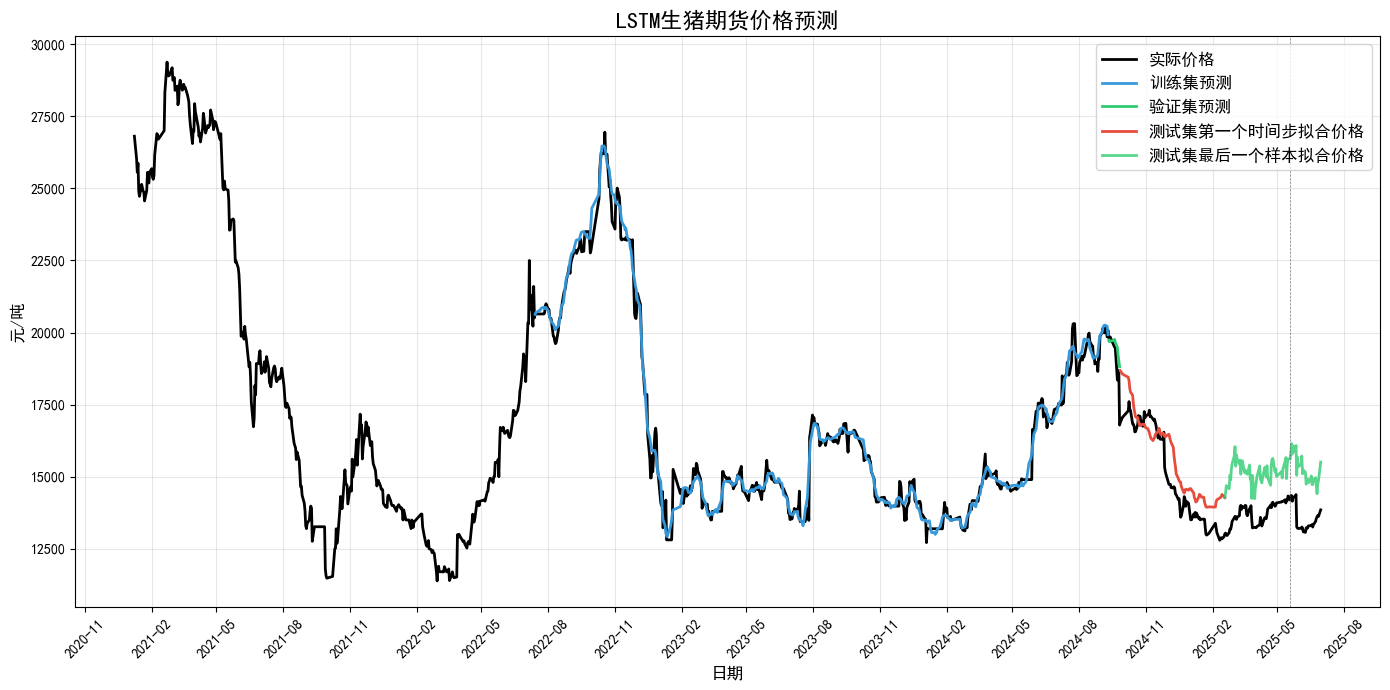

In [21]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用黑体显示中文
plt.rcParams['axes.unicode_minus'] = False    # 正常显示负号

# 1. 数据准备与划分
star_1_1476_with_dates = df[['lh00close']].iloc[0:1082]

# 调用你提供的划分函数
train_star_end_day, val_star_end_day, test1_star_end_day, test90_star_end_day \
    = split_data(star_1_1476_with_dates, input_seq_len, output_seq_len, train_ratio_param, val_ratio_date)

# 3. 绘图
plt.figure(figsize=(14, 7))

# 1. 绘制历史真实价格 (黑色实线)
plt.plot(df['lh00close'].iloc[0:1082].index,  
         df['lh00close'].iloc[0:1082],  
         '-', color='black', linewidth=2, label='实际价格')

# 2. 绘制训练集拟合价格 (橙色虚线)
plt.plot(train_star_end_day.index, pred_train_real[:, 0, 0], linestyle='-', color='#3498DB', alpha=0.98, linewidth=2, label='训练集预测')

# 3. 绘制验证集拟合价格 (蓝色点划线)
plt.plot(val_star_end_day.index, pred_val_real[:, 0, 0], '-', color='#2ECC71', linewidth=2, label='验证集预测')

# 4. 绘制测试集预测 (红色点线)
#绘制测试集第一个时间步拟合价格
plt.plot(test1_star_end_day.index,  
         pred_test_real[:, 0, 0], 
        '-',
         color='#E74C3C', 
         alpha=1,
         markersize=7,
         markevery=15,
         linewidth=2,
         label='测试集第一个时间步拟合价格')
#绘制测试集最后一个样本拟合价格
plt.plot(test90_star_end_day.index,  
         pred_test_real[-1, :, 0], 
        '-',
         color='#2ECC71', 
         alpha=0.8,
         linewidth=2,
         markersize=7,  # 标记大小
         markerfacecolor='green',  # 标记内部颜色
         markeredgecolor='darkgreen',  # 标记边框颜色
         markevery=25,
         label='测试集最后一个样本拟合价格')

# 4. 图表美化
plt.title('LSTM生猪期货价格预测', fontsize=16)
plt.xlabel('日期', fontsize=12)
plt.ylabel('元/吨', fontsize=12) # 修正单位错别字 "顿" -> "吨"
plt.legend(loc='upper right', fontsize=12)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

# ===================== 【新增】最后30个时间步 竖线 =====================
full_index = df['lh00close'].iloc[0:1082].index  # 你绘制的全部数据索引
split_pos = len(full_index) - 30  # 倒数第30个点的位置
vertical_line_date = full_index[split_pos]  # 获取对应日期

# 画竖线：红色、虚线、透明度0.8
plt.axvline(
    x=vertical_line_date,
    color='#555555',
    linestyle='--',
    linewidth=0.5,
    alpha=0.8,
    label='最后30个时间步起始线'
)
# ======================================================================

# 设置时间轴格式 (每3个月显示一个刻度)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

# 保存图片
save_path = 'LSTM期货预测走势图.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"✅ 图片已保存至: {save_path}")

plt.show()

In [22]:
# ===================== 【新增】导出四个拟合价格到Excel =====================
import pandas as pd

# 1. 将四个预测序列转换为带日期索引的Series（自动对齐时间）
# 训练集预测（每个样本第一个时间步）
train_pred = pd.Series(
    pred_train_real[:, 0, 0], 
    index=train_star_end_day.index, 
    name='训练集预测价格'
)

# 验证集预测（每个样本第一个时间步）
val_pred = pd.Series(
    pred_val_real[:, 0, 0], 
    index=val_star_end_day.index, 
    name='验证集预测价格'
)

# 测试集第一个时间步预测（每个样本第一个时间步）
test1_pred = pd.Series(
    pred_test_real[:, 0, 0], 
    index=test1_star_end_day.index, 
    name='测试集第一个时间步预测'
)

# 测试集最后一个样本预测（未来90天完整预测）
test_last_pred = pd.Series(
    pred_test_real[-1, :, 0], 
    index=test90_star_end_day.index, 
    name='测试集最后一个样本预测'
)

# 2. 合并所有预测序列（按日期自动对齐，缺失值显示为NaN）
prediction_df = pd.concat([
    train_pred,
    val_pred,
    test1_pred,
    test_last_pred
], axis=1)

# 3. 重置索引，将日期作为第一列（Excel中更直观）
prediction_df = prediction_df.reset_index()
prediction_df.rename(columns={'index': '日期'}, inplace=True)

# 4. 保存到Excel文件（需要安装openpyxl库：pip install openpyxl）
excel_save_path = 'EEMD-LSTM-1.8-预测结果对比.xlsx'
prediction_df.to_excel(
    excel_save_path, 
    index=False,  # 不保存pandas默认的数字索引
    engine='openpyxl',
    float_format='%.2f'  # 价格保留两位小数
)

# 5. 打印确认信息
print(f"\n✅ 预测结果已成功导出到Excel: {excel_save_path}")
print(f"📊 表格总行数: {len(prediction_df)}")
print(f"📋 表格列名: {list(prediction_df.columns)}")
print(f"⚠️  说明: 空白单元格(NaN)表示该日期没有对应的预测值")
# ======================================================================


✅ 预测结果已成功导出到Excel: EEMD-LSTM-1.8-预测结果对比.xlsx
📊 表格总行数: 717
📋 表格列名: ['日期', '训练集预测价格', '验证集预测价格', '测试集第一个时间步预测', '测试集最后一个样本预测']
⚠️  说明: 空白单元格(NaN)表示该日期没有对应的预测值
